# Analysis of Yahoo's Open_NSFW Information Retrieval

We will be comparing the amount of information that Yahoo's open_nsfw classifier can on our dataset. In this analysis, we took a total of 33,304 approved photos from Nanameue, and 1873 photos that are certainly nude. Some of the photos from the nude set are from our decline/kenta dataset, while some are loaded online.

We are interested in two things:
1. The overall accuracy of the classifier
2. The amount of true positives/negatives that the classifier is able to identify (i.e. recall)

In [ ]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd

We first load the NSFW scores for all images from the approved set. Then, for every cutoff i in range(0, 1, by=0.01), we calculate the fraction of images that have NSFW score lower than i. Here we are comparing different decision boundaries. Note that here we're constructing the empirical cumulative distribution function (ECDF) of the set.

In [216]:
lst = pickle.load(open('NSFW_scores.pkl'))
arr = []
for i in lst:
    arr.append(i[2])
arr = np.asarray(arr)

s = []
for i in np.arange(0,1,0.01):
    t = sum(arr < i)/float(arr.shape[0])
    s.append([i,t])
s = np.asarray(s)

In [234]:
df_approved = pd.DataFrame(s, columns=['Cutoffs', 'Approved_Recall'])

Here we do the same for nude photos. However, we record the fraction of images that have NSFW score $\underline{above}$ the cutoff i. [This would give us the ECDF with the inverted x-axis]

In [218]:
nudes = pickle.load(open('nudes_NSFW_scores.pkl'))
nudes_arr = []
for i in nudes:
    nudes_arr.append(i[2])
nudes_arr = np.asarray(nudes_arr)

t = []
for i in np.arange(0,1,0.01):
    tmp = sum(nudes_arr > i)/float(nudes_arr.shape[0])
    t.append([i,tmp])
t = np.asarray(t)

In [219]:
df_nudes = pd.DataFrame(t, columns=['Cutoffs', 'Nudes_Recall'])

Below is the plot of the two curves. Note how they intersect at $\text{cutoff}_{optimal} = 0.33$. Here the recall is roughly 96% for each set. It is optimal in the sense that it compromises between the two curves; if we decreased the cutoff (something lower than 0.33), then we would be able to recall more of nude photos, but less of approved photos. On the other hand, if we increased the boundary to something above 0.33, then we would be able to recall more approved photos and less of nude photos.

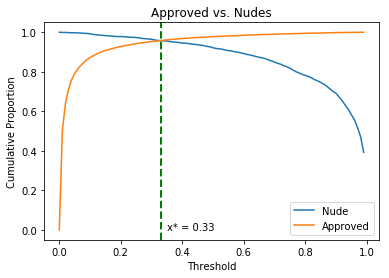

In [220]:
plt.plot(t[:,0], t[:,1])
plt.plot(s[:,0], s[:,1])
plt.xlabel('Threshold')
plt.ylabel('Cumulative Proportion')
plt.title('Approved vs. Nudes')
plt.legend(['Nude', 'Approved'])

x_opt = np.where(np.abs(s[:,1]-t[:,1]) < 0.001)[0][0]/100. #find the intersection of the two curves
plt.axvline(x = x_opt, color='green', linestyle='dashed', linewidth=2)
plt.text(x=0.35, y=0, s='x* = 0.33')
plt.show()

There's one important thing to consider: our data is highly imbalance, and the optimal point above may compromise too much for nude photos, when it's just a small fraction of our dataset. This leads the total recall proportion (and also the accuracy) to be optimal for each set, assuming they are the same size. One thing that we can do to mitigate this problem is to weight the recall by the size of the set. This would allow us to increase the overall recall/accuracy. This approach, however, would reduce the recall for the nude set, because the approved set has a higher weight, so it would push the cutoff up to encapsulate more data points. So, in terms of automation, there might be more slips of nude images classified as approved, but we would be able to calculate A LOT more of approved photos with high confidence!

In [224]:
df_combined = df_approved
df_combined['Nudes_Recall'] = df_nudes['Nudes_Recall']
df_combined['Approved*33,304'] = df_combined['Approved_Recall']*33304
df_combined['Nudes*1873'] = df_combined['Nudes_Recall']*1873
df_combined['Total Recall Proportion'] = (df_combined['Approved*33,304'] + df_combined['Nudes*1873'])/(33304 + 1873)
df_combined['Total Recall'] = df_combined['Approved*33,304'] + df_combined['Nudes*1873']

In [225]:
df_combined

,Cutoffs,Approved_Recall,Nudes_Recall,"Approved*33,304",Nudes*1873,Total Recall Proportion,Total Recall
0,0.00,0.000000,1.000000,0.0,1873.0,0.053245,1873.0
1,0.01,0.502943,0.998932,16750.0,1871.0,0.529352,18621.0
2,0.02,0.639803,0.998932,21308.0,1871.0,0.658925,23179.0
3,0.03,0.711896,0.997864,23709.0,1869.0,0.727123,25578.0
4,0.04,0.758888,0.997330,25274.0,1868.0,0.771584,27142.0
5,0.05,0.791376,0.997330,26356.0,1868.0,0.802342,28224.0
6,0.06,0.813506,0.996797,27093.0,1867.0,0.823265,28960.0
7,0.07,0.832092,0.995729,27712.0,1865.0,0.840805,29577.0
8,0.08,0.847346,0.994661,28220.0,1863.0,0.855189,30083.0
9,0.09,0.861758,0.994127,28700.0,1862.0,0.868806,30562.0


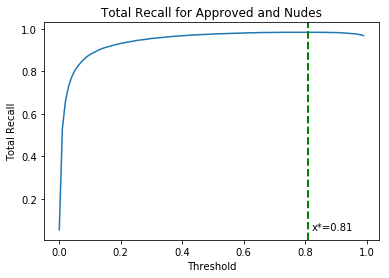

In [230]:
plt.plot(df_combined['Cutoffs'], df_combined['Total Recall Proportion'])
plt.xlabel('Threshold')
plt.ylabel('Total Recall')
plt.title('Total Recall for Approved and Nudes')
max_ind = np.where(df_combined['Total Recall Proportion'] == np.max(df_combined['Total Recall Proportion']))[0][0]/100.
plt.axvline(x = max_ind, linestyle='dashed', c = 'green', linewidth = 2)
plt.text(x=0.82, y=0.05, s='x*=0.81')
plt.show()

The plot above is the total recall percentage for the entire set. The maximum occurs at x = 0.81. If you refer to the table above under Total Recall, you can see that the total recall is 34,589 out of 33,304+1873=35,177, which is a great 98.33% overall accuracy!